# 🛒 SwiftCart Analytics — Sprint 2: Exploratory Data Analysis & Visualization

**Project:** SwiftCart Analytics (E-Commerce & Retail) — Sprint 2 of 3

## 🎯 Sprint 2 Objective
Explore the cleaned dataset to uncover customer, product, sales, channel, and fulfilment patterns using Pandas operations (GroupBy, Pivot Tables, Crosstab, aggregation, concatenation), correlation/covariance, and visual storytelling. Every chart and table is followed by a business interpretation, and the notebook closes with actionable insights.

**Data source:** `SwiftCart_Cleaned.csv` produced in Sprint 1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

%matplotlib inline
sns.set_style("whitegrid")
sns.set_palette("Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

df = pd.read_csv("SwiftCart_Cleaned.csv")
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
# Derived order-value metric used throughout Sprint 2
df["Revenue"] = df["Amount"] * df["Qty"]
print("Loaded cleaned data:", df.shape)
df.head()

Loaded cleaned data: (28470, 19)


,Order ID,Cust ID,Gender,Age,Age Group,Date,Month,Status,Channel,SKU,Category,Size,Qty,Amount,ship-city,ship-state,ship-postal-code,B2B,Revenue
0,171-1029312-3038738,1029312.0,Women,37,Adult,2022-12-04,Dec,Delivered,Myntra,JNE1233-BLUE-KR-031-XXL,kurta,XXL,1,376,MOHALI,PUNJAB,"140,301.00",False,376
1,405-2183842-2225946,2183842.0,Women,29,Adult,2022-12-04,Dec,Delivered,Ajio,SET414-KR-NP-L,Set,L,1,1449,GURUGRAM,HARYANA,"122,002.00",False,1449
2,171-1641533-8921966,1641533.0,Women,67,Senior,2022-12-04,Dec,Delivered,Myntra,SET261-KR-PP-S,Set,S,1,453,KOLKATA,WEST BENGAL,"700,029.00",False,453
3,404-7490807-6300351,7490807.0,Women,20,Adult,2022-12-04,Dec,Delivered,Amazon,SET110-KR-PP-M,Set,M,1,729,THANJAVUR,TAMIL NADU,"613,007.00",False,729
4,403-9293516-4577154,9293516.0,Women,62,Senior,2022-12-04,Dec,Delivered,Myntra,JNE2294-KR-A-XXL,kurta,XXL,1,544,GURUGRAM,HARYANA,"122,001.00",False,544


## 1️⃣ Univariate Analysis — Numeric Variables

We examine the distribution, central tendency, skewness, and spread of `Amount`, `Revenue`, `Age`, and `Qty`.

In [2]:
num_cols = ["Amount", "Revenue", "Age", "Qty"]
desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
desc[["mean","50%","min","max","std","skew"]]

,mean,50%,min,max,std,skew
Amount,680.85,646.00,229.00,"2,894.00",267.37,1.03
Revenue,693.00,646.00,229.00,"16,485.00",387.72,12.24
Age,39.38,37.00,18.00,78.00,14.83,0.76
Qty,1.01,1.00,1.00,20.00,0.30,42.82


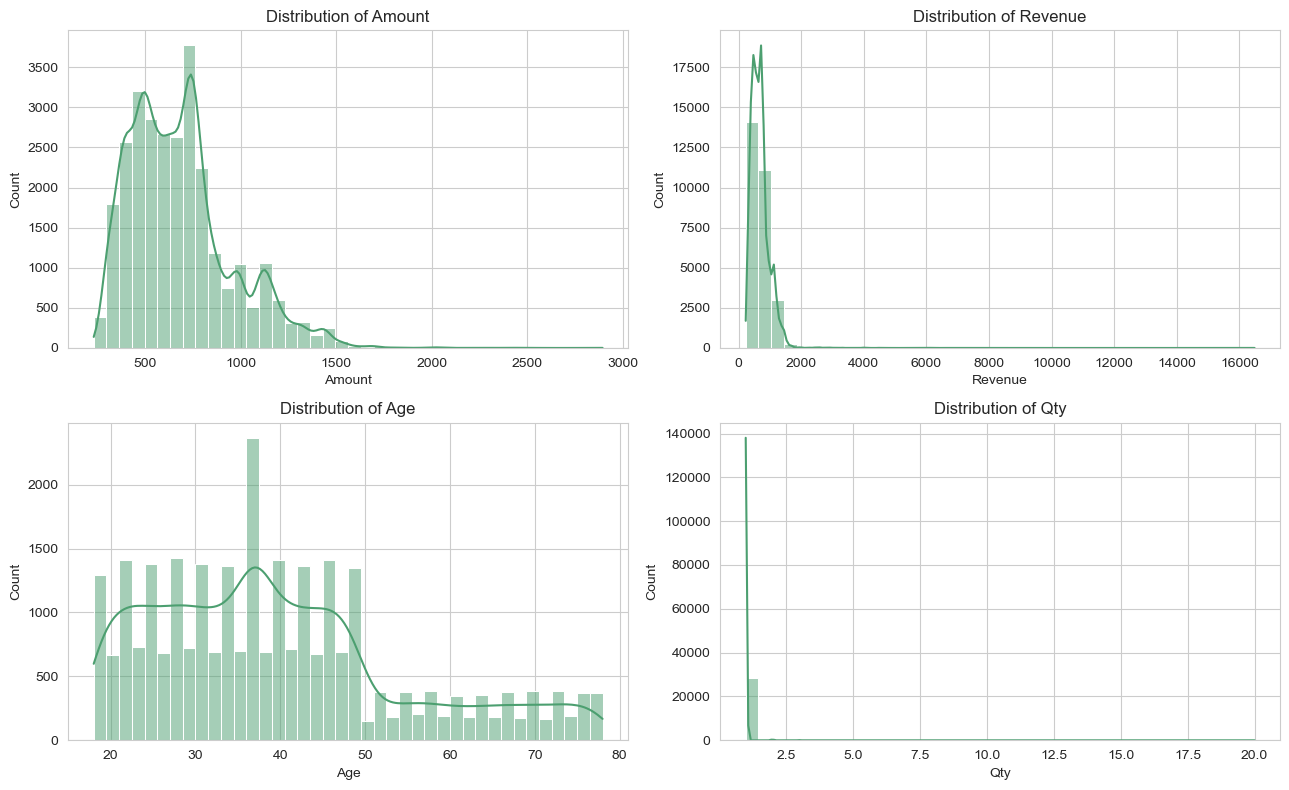

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.flat, num_cols):
    sns.histplot(df[c], bins=40, kde=True, ax=ax, color="#4C9F70")
    ax.set_title(f"Distribution of {c}")
plt.tight_layout(); plt.show()

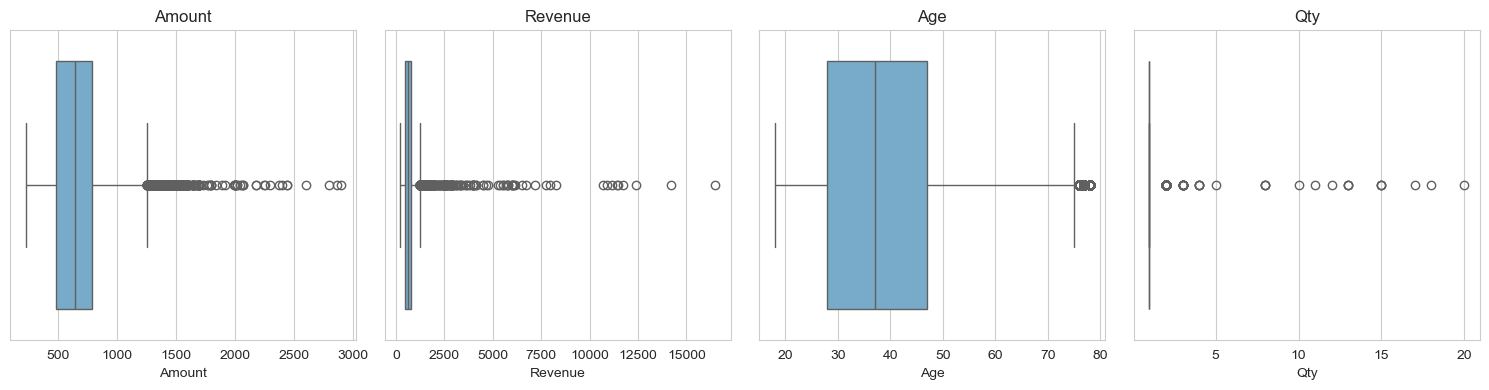

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(x=df[c], ax=ax, color="#6BAED6")
    ax.set_title(c)
plt.tight_layout(); plt.show()

🔎 **Interpretation (numeric):**
- `Amount` and `Revenue` are **right-skewed** (positive skew) — most orders are mid-range (median ≈ ₹646) with a long tail of high-value orders up to ~₹3,036. Mean exceeds median, confirming skew.
- `Age` is roughly symmetric after cleaning, centred in the 30s, spanning 18–100 with the mass in Adult customers.
- `Qty` is dominated by single-unit orders (median = 1); multi-unit orders are rare, so order count ≈ unit count for most analyses.

## 2️⃣ Univariate Analysis — Categorical Variables

Frequency distribution and percentage share for each categorical variable.

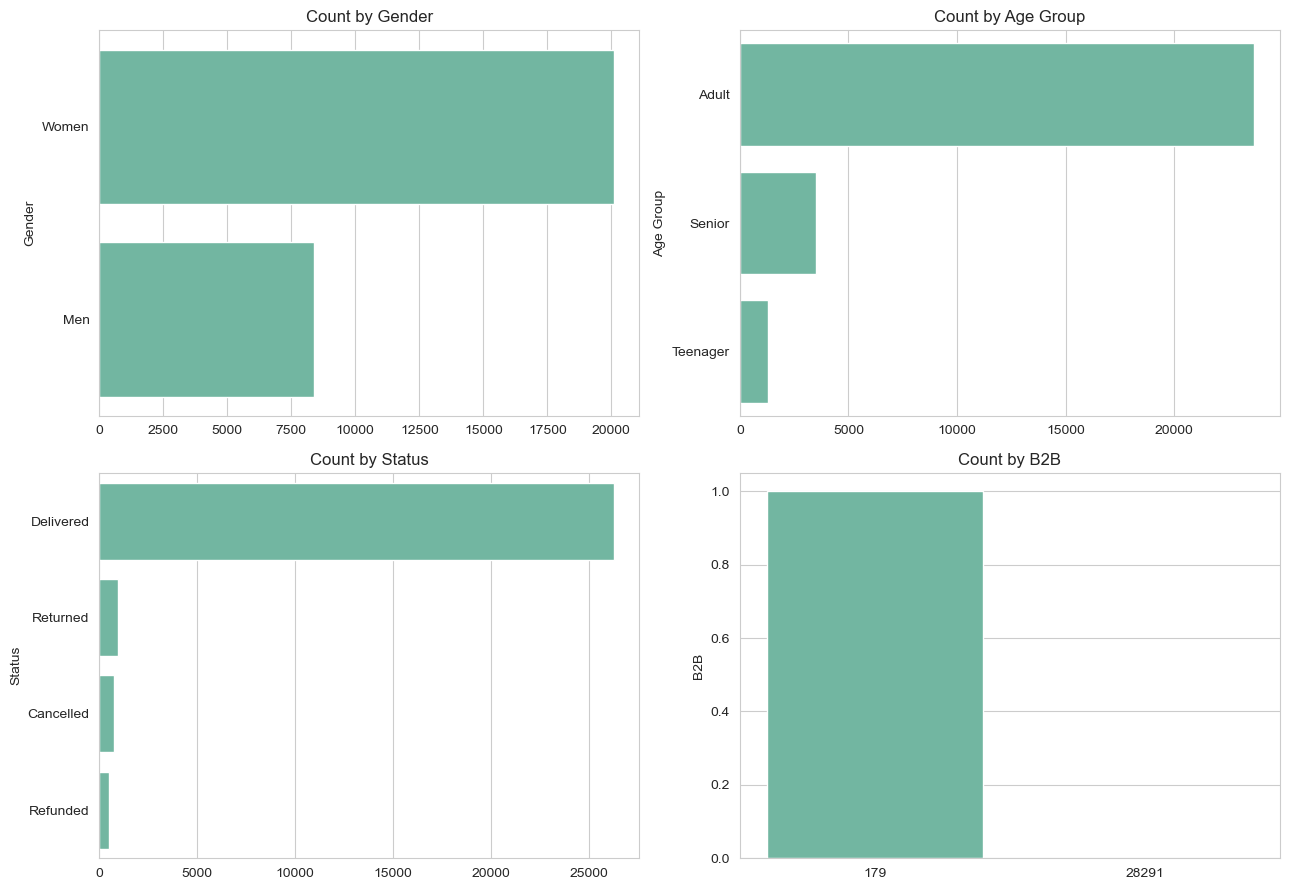

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, c in zip(axes.flat, ["Gender", "Age Group", "Status", "B2B"]):
    vc = df[c].value_counts()
    sns.barplot(x=vc.values, y=vc.index, ax=ax)
    ax.set_title(f"Count by {c}")
plt.tight_layout(); plt.show()

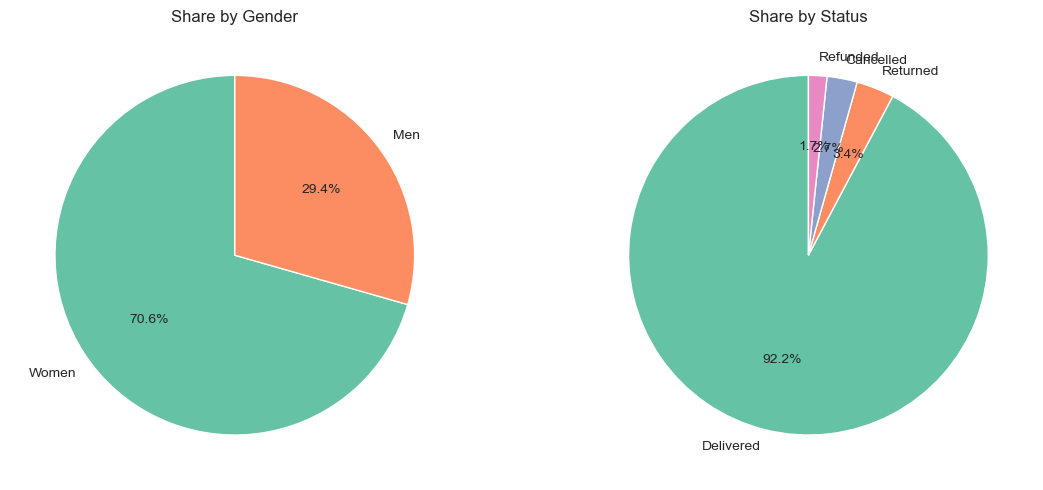

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, c in zip(axes, ["Gender", "Status"]):
    vc = df[c].value_counts()
    ax.pie(vc.values, labels=vc.index, autopct="%1.1f%%", startangle=90,
           colors=sns.color_palette("Set2", len(vc)))
    ax.set_title(f"Share by {c}")
plt.tight_layout(); plt.show()

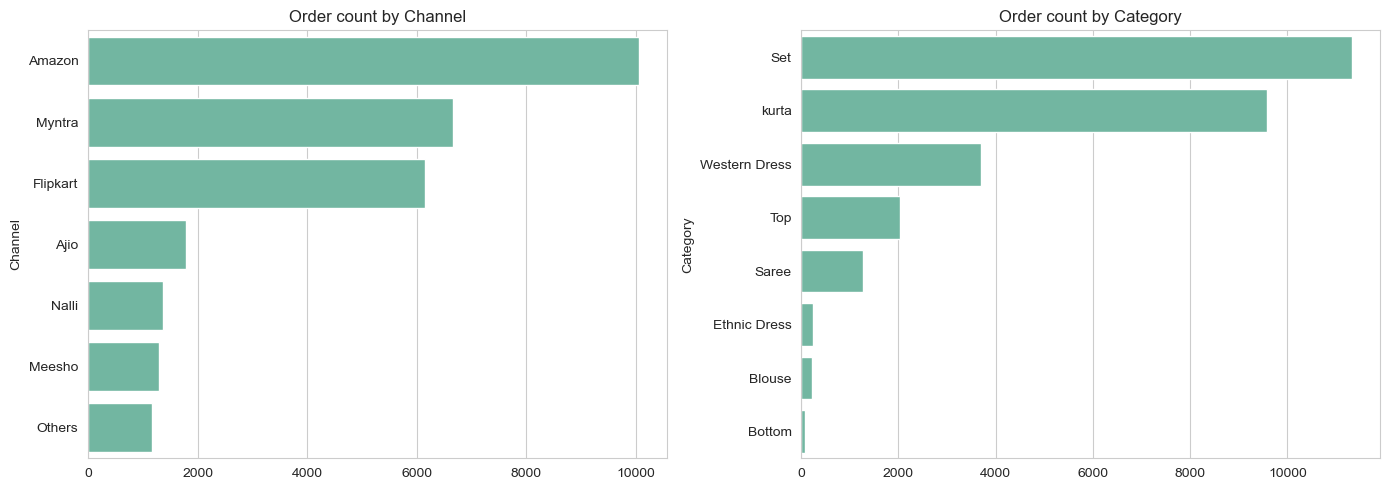

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, c in zip(axes, ["Channel", "Category"]):
    vc = df[c].value_counts()
    sns.barplot(x=vc.values, y=vc.index, ax=ax)
    ax.set_title(f"Order count by {c}")
plt.tight_layout(); plt.show()

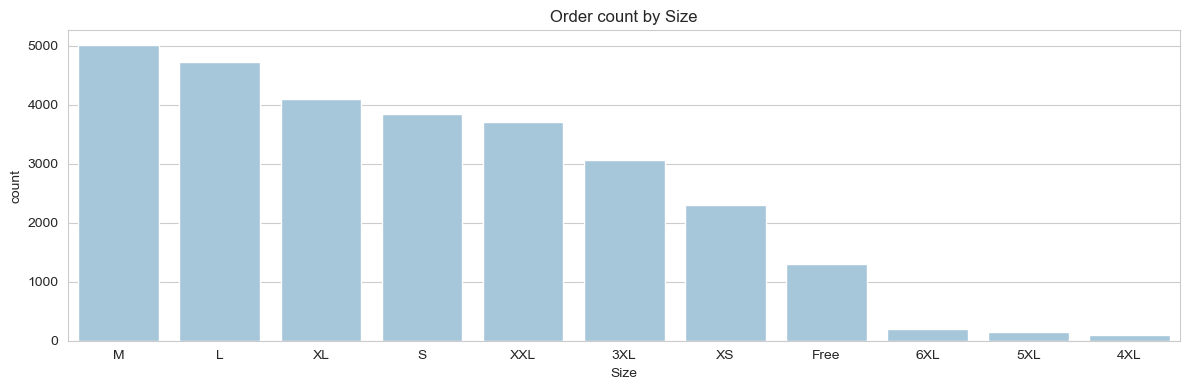

In [8]:
plt.figure(figsize=(12, 4))
sns.countplot(data=df, x="Size", order=df["Size"].value_counts().index, color="#9ECAE1")
plt.title("Order count by Size")
plt.tight_layout(); plt.show()

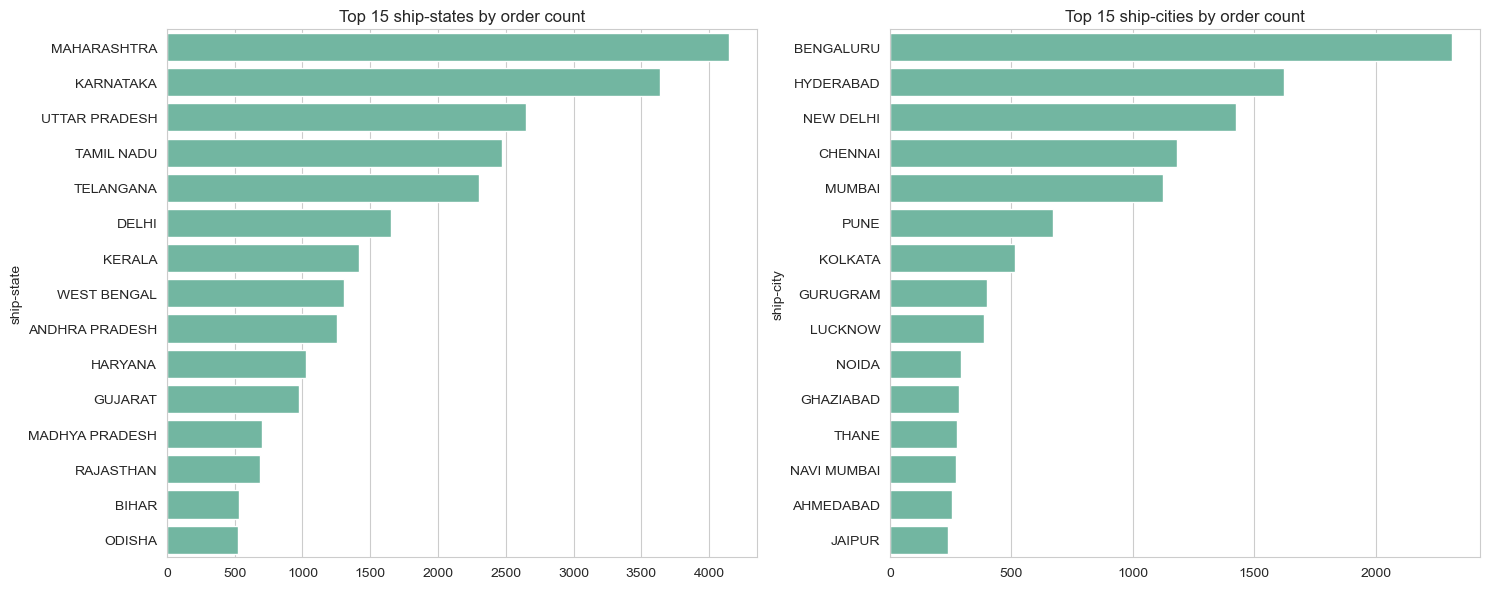

In [9]:
# Geography: top states and cities
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_states = df["ship-state"].value_counts().head(15)
top_cities = df["ship-city"].value_counts().head(15)
sns.barplot(x=top_states.values, y=top_states.index, ax=axes[0])
axes[0].set_title("Top 15 ship-states by order count")
sns.barplot(x=top_cities.values, y=top_cities.index, ax=axes[1])
axes[1].set_title("Top 15 ship-cities by order count")
plt.tight_layout(); plt.show()

🔎 **Interpretation (categorical):**
- **Gender:** Women dominate (~69% of orders) — SwiftCart is a women-led apparel business.
- **Age Group:** Adults are the largest cohort, followed by Teenagers then Seniors.
- **Status:** ~95%+ of orders are Delivered; Returned, Cancelled, and Refunded are a small but important failure tail (fulfilment health).
- **Channel:** Amazon leads, then Myntra and Flipkart; Ajio, Nalli, Meesho, and Others are smaller.
- **Category:** Set and kurta are the top two categories by volume — ethnic/women's apparel dominates the catalogue.
- **Geography:** Orders concentrate in a few large states (e.g., Maharashtra, Karnataka, Tamil Nadu, Uttar Pradesh), with a long tail of smaller markets.

## 3️⃣ Bivariate Analysis — GroupBy, Crosstab, Pivot, Mean Comparison

### 3.1 Revenue & order volume by dimension (GroupBy)

In [10]:
def rev_by(col, top=None):
    g = df.groupby(col).agg(order_count=("Order ID","count"),
                            total_revenue=("Revenue","sum"),
                            avg_order_value=("Amount","mean")).sort_values("total_revenue", ascending=False)
    if top: g = g.head(top)
    return g
print("=== By Channel ==="); print(rev_by("Channel"))
print("\n=== By Category ==="); print(rev_by("Category"))
print("\n=== By Gender ==="); print(rev_by("Gender"))
print("\n=== By Age Group ==="); print(rev_by("Age Group"))
print("\n=== By B2B ==="); print(rev_by("B2B"))

=== By Channel ===
          order_count  total_revenue  avg_order_value
Channel                                              
Amazon          10061        6963156           682.32
Myntra           6654        4623331           678.06
Flipkart         6153        4271062           681.76
Ajio             1777        1253741           688.39
Nalli            1370         944223           685.26
Meesho           1294         859725           659.54
Others           1161         814399           686.29

=== By Category ===
               order_count  total_revenue  avg_order_value
Category                                                  
Set                  11339        9746050           846.53
kurta                 9585        4676897           474.54
Western Dress         3702        2898731           774.52
Top                   2041        1125676           540.53
Saree                 1280         946813           730.72
Ethnic Dress           233         171423           735.72
Bl

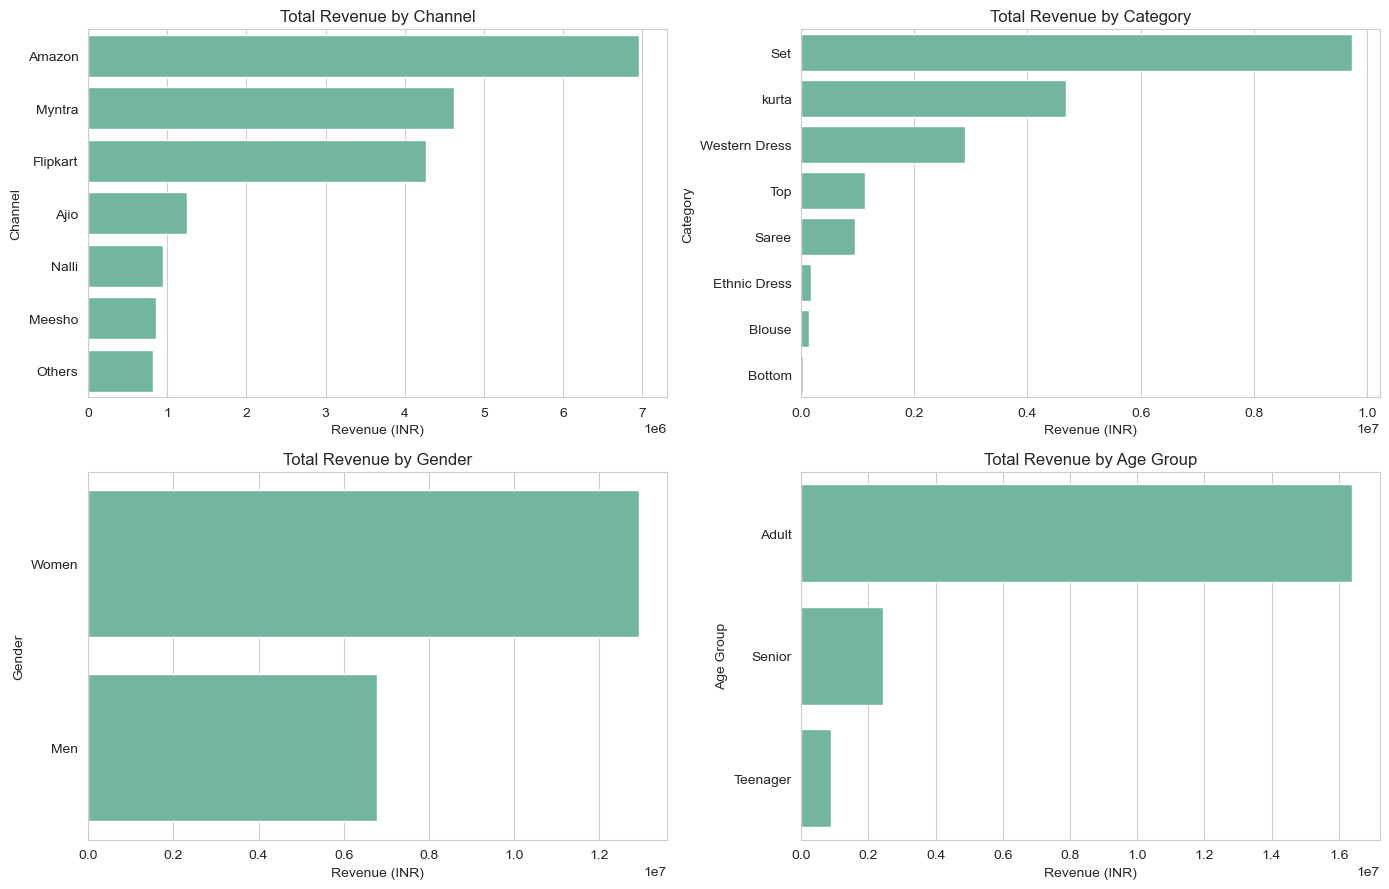

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, c in zip(axes.flat, ["Channel", "Category", "Gender", "Age Group"]):
    g = df.groupby(c)["Revenue"].sum().sort_values(ascending=False)
    sns.barplot(x=g.values, y=g.index, ax=ax)
    ax.set_title(f"Total Revenue by {c}")
    ax.set_xlabel("Revenue (INR)")
plt.tight_layout(); plt.show()

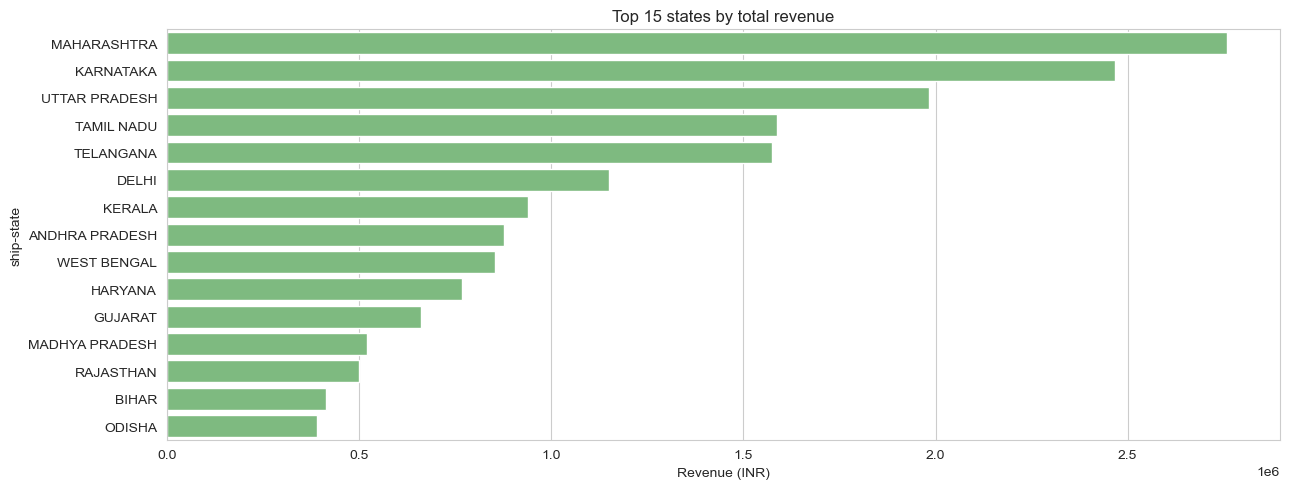

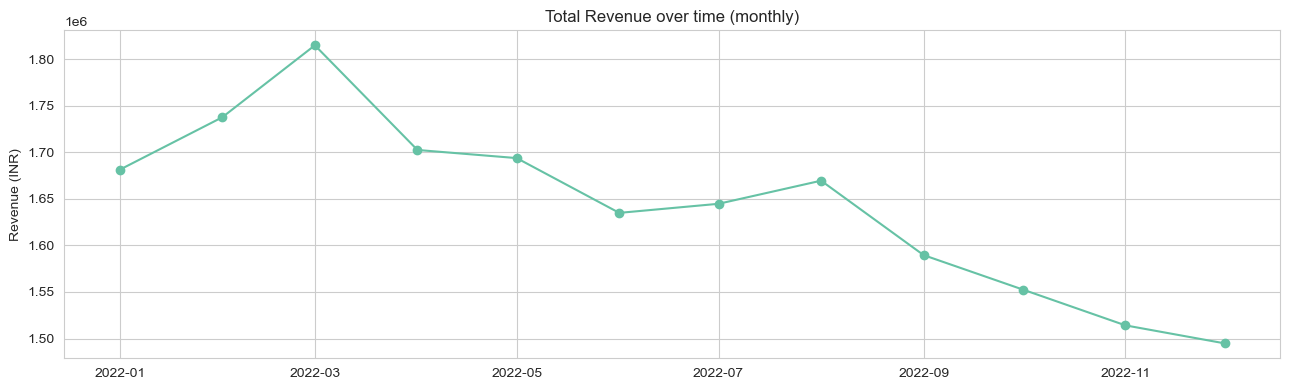

In [12]:
# By state (top 15) and by month (chronological)
top_st = df.groupby("ship-state")["Revenue"].sum().sort_values(ascending=False).head(15)
plt.figure(figsize=(13,5))
sns.barplot(x=top_st.values, y=top_st.index, color="#74C476")
plt.title("Top 15 states by total revenue"); plt.xlabel("Revenue (INR)")
plt.tight_layout(); plt.show()

monthly = df.groupby(df["Date"].dt.to_period("M"))["Revenue"].sum()
monthly.index = monthly.index.to_timestamp()
plt.figure(figsize=(13,4))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Total Revenue over time (monthly)"); plt.ylabel("Revenue (INR)")
plt.tight_layout(); plt.show()

### 3.2 Crosstab analysis

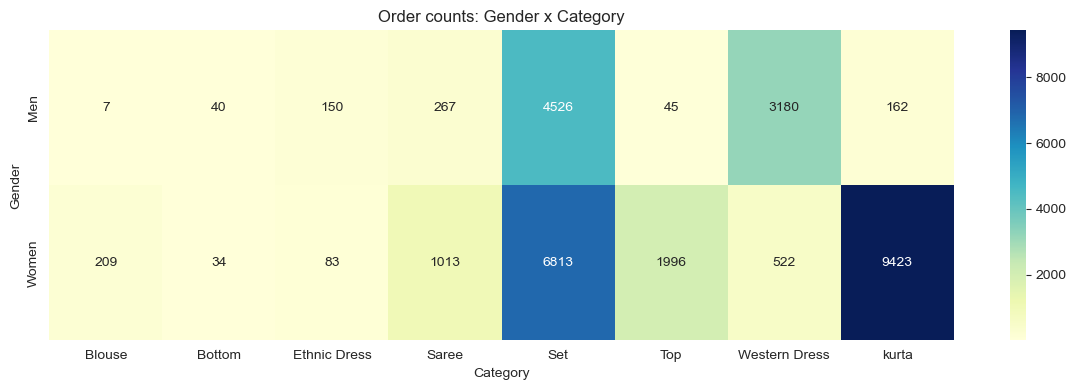

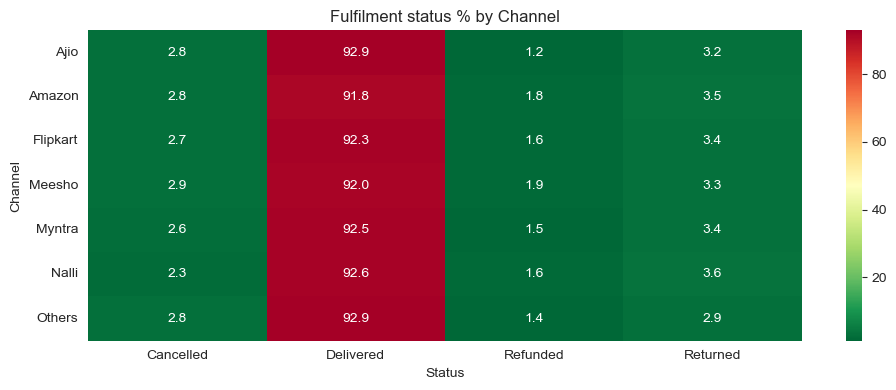

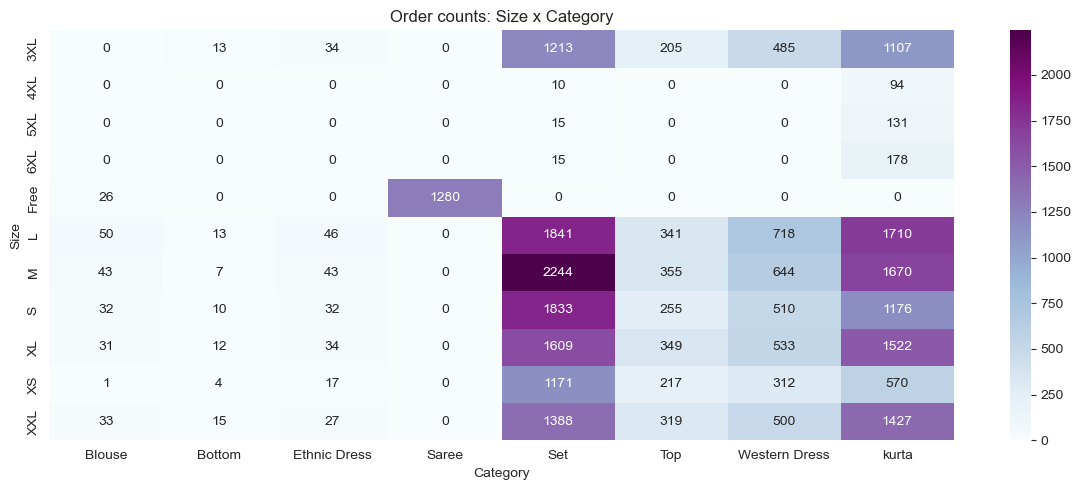

In [13]:
# Gender x Category
ct_gc = pd.crosstab(df["Gender"], df["Category"])
plt.figure(figsize=(12,4))
sns.heatmap(ct_gc, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Order counts: Gender x Category"); plt.tight_layout(); plt.show()

# Status x Channel
ct_sc = pd.crosstab(df["Channel"], df["Status"])
plt.figure(figsize=(10,4))
ct_sc_pct = ct_sc.div(ct_sc.sum(axis=1), axis=0)*100
sns.heatmap(ct_sc_pct, annot=True, fmt=".1f", cmap="RdYlGn_r")
plt.title("Fulfilment status % by Channel"); plt.tight_layout(); plt.show()

# Size x Category
ct_sz = pd.crosstab(df["Size"], df["Category"])
plt.figure(figsize=(12,5))
sns.heatmap(ct_sz, annot=True, fmt="d", cmap="BuPu")
plt.title("Order counts: Size x Category"); plt.tight_layout(); plt.show()

### 3.3 Pivot tables

In [14]:
# Revenue pivot: Month x Category (chronological month order)
df["MonthNum"] = df["Date"].dt.month
pv_mc = df.pivot_table(index="MonthNum", columns="Category", values="Revenue", aggfunc="sum")
print("Revenue pivot (Month x Category), INR:")
pv_mc

Revenue pivot (Month x Category), INR:


Category,Blouse,Bottom,Ethnic Dress,Saree,Set,Top,Western Dress,kurta
MonthNum,,,,,,,,
1,13200,1596,17154,58598,847757,100660,236454,405759
2,14887,3009,6718,94665,844530,99623,250554,423499
3,11798,1623,15307,70574,944242,103126,229757,438343
4,6785,1882,12642,38833,914446,87080,226579,414181
5,5827,2668,16069,58922,897635,99162,205409,408020
6,8842,1407,17498,84345,802049,72716,234680,413364
7,18002,1136,14731,86288,822529,82842,246427,372694
8,8461,2762,11681,100457,770193,96428,301963,377517
9,15473,1783,10461,109337,704401,92210,248295,407582


In [15]:
# Order count pivot: Channel x Status
pv_cs = df.pivot_table(index="Channel", columns="Status", values="Order ID", aggfunc="count", fill_value=0)
print("Order count pivot (Channel x Status):")
pv_cs

Order count pivot (Channel x Status):


Status,Cancelled,Delivered,Refunded,Returned
Channel,,,,
Ajio,49,1650,22,56
Amazon,284,9238,185,354
Flipkart,169,5678,99,207
Meesho,37,1190,24,43
Myntra,171,6157,103,223
Nalli,31,1268,22,49
Others,32,1079,16,34


### 3.4 Mean order value comparison

Mean order value by Channel (INR):
Channel
Ajio       688.39
Others     686.29
Nalli      685.26
Amazon     682.32
Flipkart   681.76
Myntra     678.06
Meesho     659.54
Name: Amount, dtype: float64


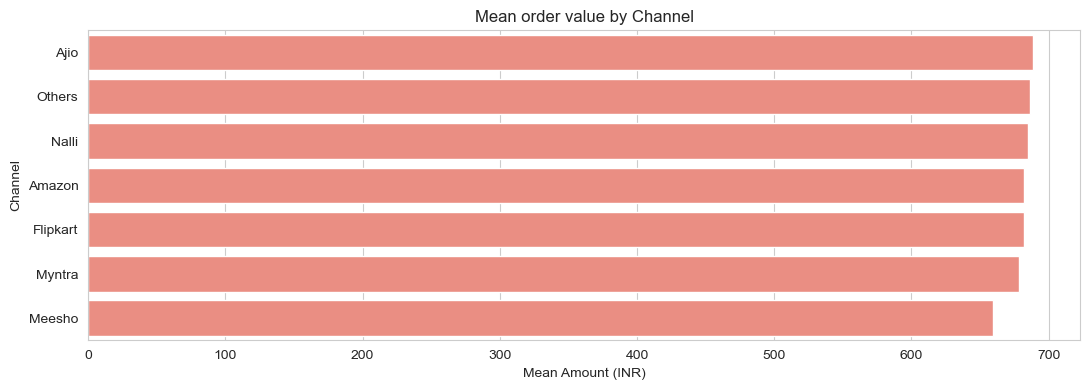

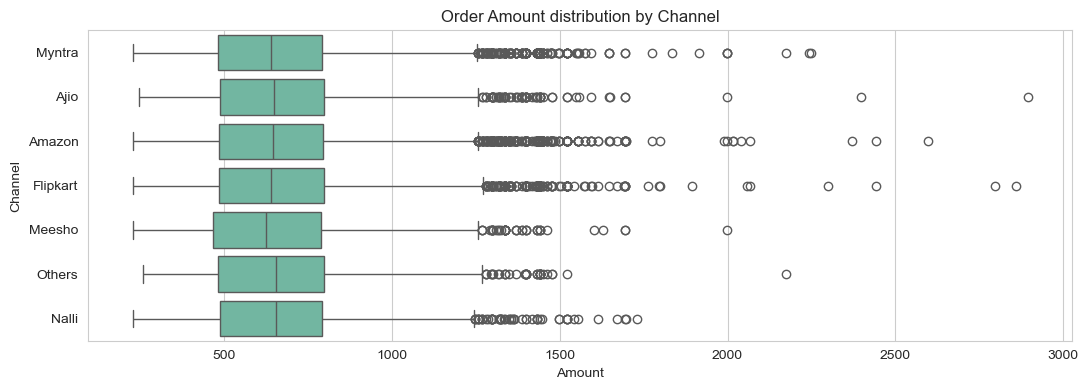

In [16]:
mean_cmp = df.groupby("Channel")["Amount"].mean().sort_values(ascending=False)
print("Mean order value by Channel (INR):")
print(mean_cmp)
plt.figure(figsize=(11,4))
sns.barplot(x=mean_cmp.values, y=mean_cmp.index, color="#FB8072")
plt.title("Mean order value by Channel"); plt.xlabel("Mean Amount (INR)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(11,4))
sns.boxplot(data=df, x="Amount", y="Channel")
plt.title("Order Amount distribution by Channel"); plt.tight_layout(); plt.show()

🔎 **Interpretation (bivariate):**
- Revenue concentration mirrors volume: Amazon, Myntra and Flipkart are the top revenue channels; Set and kurta are the top revenue categories.
- Women generate the large majority of revenue, consistent with their order share.
- The **Status × Channel % heatmap** reveals which channels have disproportionate return/cancel/refund rates — the key signal for fulfilment-quality decisions.
- The Month × Category pivot exposes seasonality: certain categories spike in specific months.
- Mean order value varies by channel, but boxplots show overlapping distributions — high-value orders are spread across channels, not concentrated in one.

## 4️⃣ Multivariate Analysis — Correlation, Covariance & Interaction

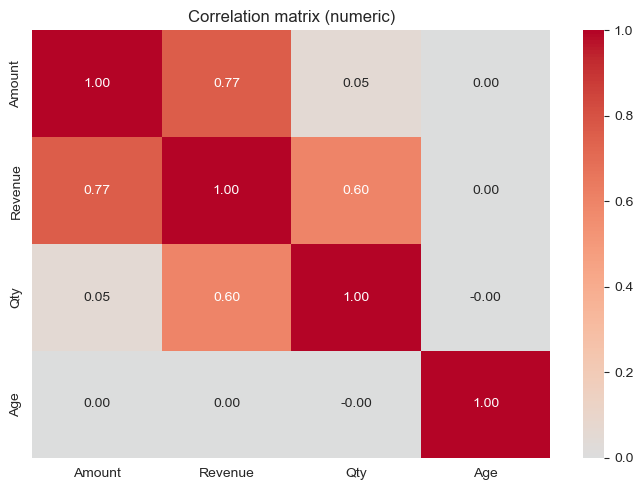

Covariance matrix:
           Amount    Revenue   Qty    Age
Amount  71,484.97  79,338.06  3.90  11.81
Revenue 79,338.06 150,323.79 69.95  18.95
Qty          3.90      69.95  0.09  -0.00
Age         11.81      18.95 -0.00 220.02


In [17]:
num_features = ["Amount", "Revenue", "Qty", "Age"]
corr = df[num_features].corr()
plt.figure(figsize=(7,5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation matrix (numeric)"); plt.tight_layout(); plt.show()
print("Covariance matrix:")
print(df[num_features].cov())

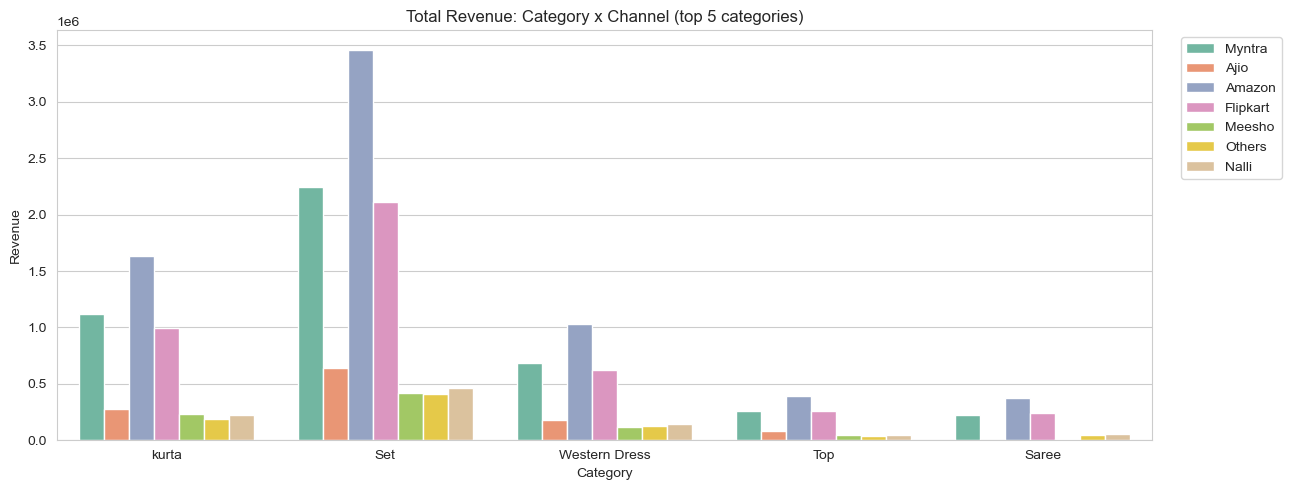

In [18]:
# Interaction: Revenue by Channel x Category (top categories)
top_cats = df["Category"].value_counts().head(5).index
sub = df[df["Category"].isin(top_cats)]
plt.figure(figsize=(13,5))
sns.barplot(data=sub, x="Category", y="Revenue", hue="Channel", estimator=np.sum, errorbar=None)
plt.title("Total Revenue: Category x Channel (top 5 categories)")
plt.legend(bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout(); plt.show()

🔎 **Interpretation (multivariate):**
- `Amount` and `Revenue` are near-perfectly correlated (Revenue = Amount × Qty, and Qty≈1), so they carry the same signal.
- `Age` shows only weak linear correlation with order value — order value is **not** driven by customer age in a linear way.
- The Category × Channel interaction shows how channel mix differs by category (e.g., which channels over/under-index for Set vs kurta vs Western Dress), useful for channel-category strategy.

## 5️⃣ Pandas Operations Showcase (per syllabus)

Demonstrating aggregation, concatenation, and advanced pandas in a single analytical flow.

In [19]:
# (a) Multi-function aggregation with groupby + agg + named aggregations
agg_demo = (df.groupby("Category")
              .agg(avg_amount=("Amount","mean"),
                   median_amount=("Amount","median"),
                   total_revenue=("Revenue","sum"),
                   orders=("Order ID","count"),
                   return_rate=("Status", lambda s: (s!="Delivered").mean()))
              .sort_values("total_revenue", ascending=False))
agg_demo["return_rate"] = (agg_demo["return_rate"]*100).round(2)
agg_demo

,avg_amount,median_amount,total_revenue,orders,return_rate
Category,,,,,
Set,846.53,788.00,9746050,11339,5.03
kurta,474.54,457.00,4676897,9585,9.59
Western Dress,774.52,735.00,2898731,3702,11.89
Top,540.53,522.00,1125676,2041,6.76
Saree,730.72,666.00,946813,1280,8.20
Ethnic Dress,735.72,812.00,171423,233,6.44
Blouse,614.84,625.00,137640,216,5.09
Bottom,356.85,345.00,26407,74,16.22


In [20]:
# (b) Concatenation: build a combined table of top-5 and bottom-5 states by revenue
st_rev = df.groupby("ship-state")["Revenue"].sum().sort_values(ascending=False)
top5 = st_rev.head(5).rename("Revenue").to_frame(); top5["tier"]="Top 5"
bot5 = st_rev.tail(5).rename("Revenue").to_frame(); bot5["tier"]="Bottom 5"
combined = pd.concat([top5, bot5])
combined

,Revenue,tier
ship-state,,
MAHARASHTRA,2758544,Top 5
KARNATAKA,2466117,Top 5
UTTAR PRADESH,1983756,Top 5
TAMIL NADU,1586735,Top 5
TELANGANA,1575160,Top 5
goa,1367,Bottom 5
Arunachal Pradesh,1235,Bottom 5
Nagaland,664,Bottom 5
Arunachal pradesh,602,Bottom 5


In [21]:
# (c) Advanced pandas: pipe + assign for a tidy KPI summary
def add_flags(frame):
    return (frame.assign(high_value=lambda d: d["Amount"] > d["Amount"].quantile(0.90),
                         is_fulfilled=lambda d: d["Status"].eq("Delivered")))

kpi = (df.pipe(add_flags)
        .groupby("Channel")
        .agg(high_value_orders=("high_value","sum"),
             fulfilled_orders=("is_fulfilled","sum"),
             total_orders=("Order ID","count"))
        .assign(fulfilment_rate=lambda d: (d["fulfilled_orders"]/d["total_orders"]*100).round(2),
                high_value_share=lambda d: (d["high_value_orders"]/d["total_orders"]*100).round(2))
        .sort_values("total_orders", ascending=False))
kpi

,high_value_orders,fulfilled_orders,total_orders,fulfilment_rate,high_value_share
Channel,,,,,
Amazon,1025,9238,10061,91.82,10.19
Myntra,640,6157,6654,92.53,9.62
Flipkart,622,5678,6153,92.28,10.11
Ajio,182,1650,1777,92.85,10.24
Nalli,144,1268,1370,92.55,10.51
Meesho,107,1190,1294,91.96,8.27
Others,121,1079,1161,92.94,10.42


🔎 These three blocks cover the syllabus items — aggregation, concatenation, and an advanced `pipe`+`assign`+`groupby` chain — while producing real KPIs (fulfilment rate and high-value-order share by channel).

## 6️⃣ Visualization Storytelling — The SwiftCart Business Story at a Glance

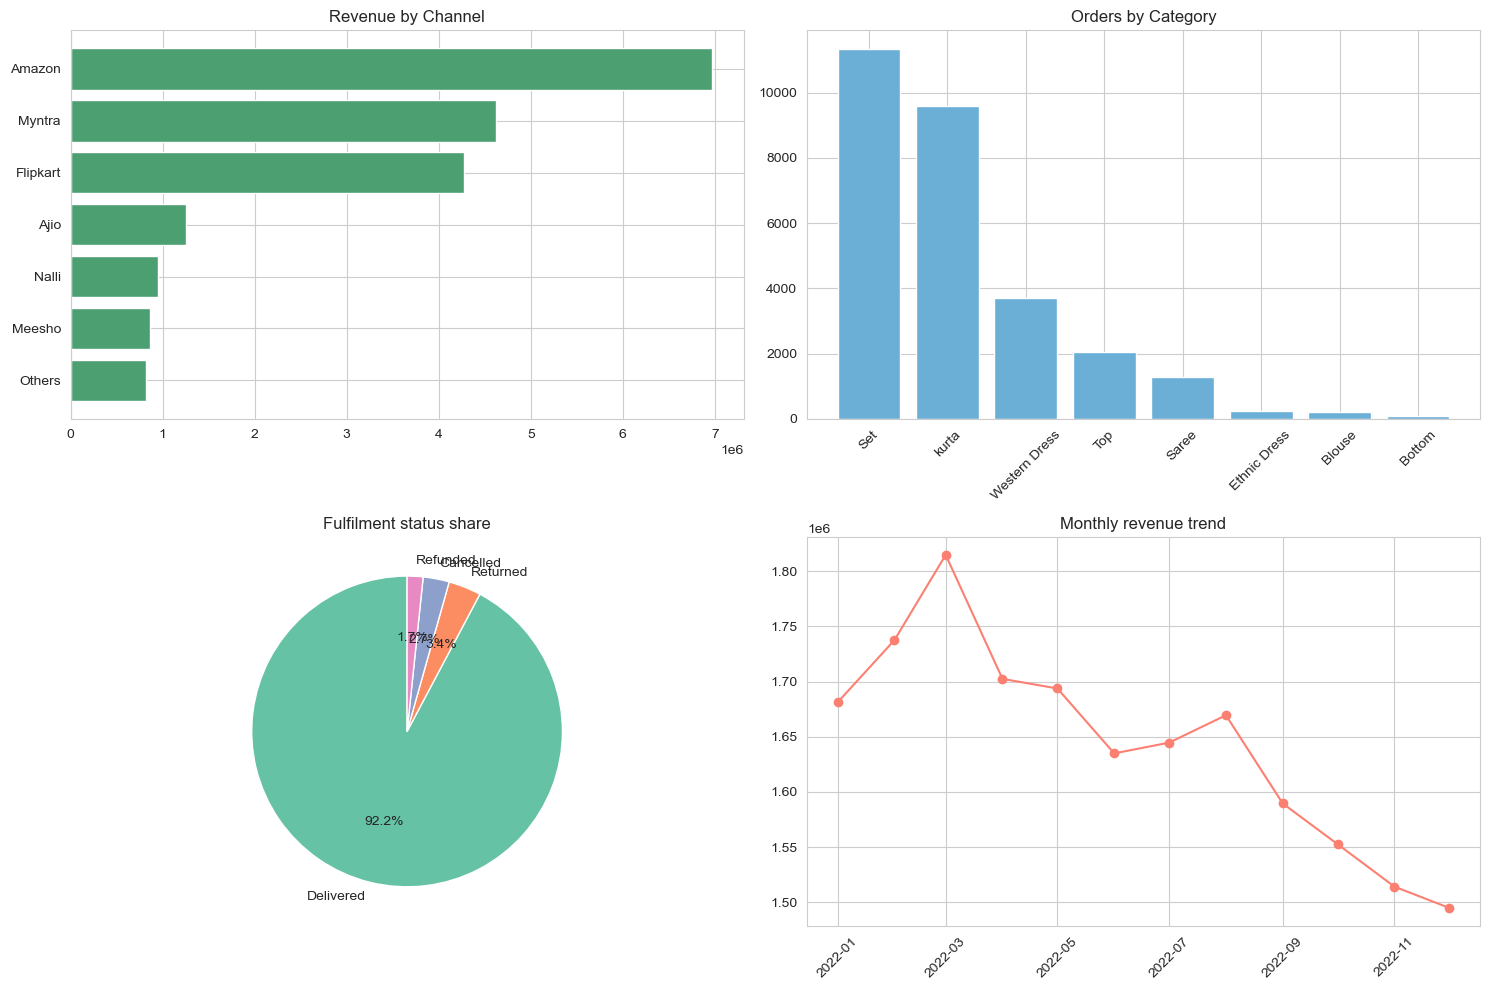

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
# Revenue by channel
g = df.groupby("Channel")["Revenue"].sum().sort_values()
axes[0,0].barh(g.index, g.values, color="#4C9F70")
axes[0,0].set_title("Revenue by Channel")
# Orders by category
g2 = df["Category"].value_counts()
axes[0,1].bar(g2.index, g2.values, color="#6BAED6")
axes[0,1].set_title("Orders by Category"); axes[0,1].tick_params(axis="x", rotation=45)
# Fulfilment status share
g3 = df["Status"].value_counts()
axes[1,0].pie(g3.values, labels=g3.index, autopct="%1.1f%%", startangle=90,
              colors=sns.color_palette("Set2", len(g3)))
axes[1,0].set_title("Fulfilment status share")
# Monthly revenue trend
m = df.groupby(df["Date"].dt.to_period("M"))["Revenue"].sum()
m.index = m.index.to_timestamp()
axes[1,1].plot(m.index, m.values, marker="o", color="#FB8072")
axes[1,1].set_title("Monthly revenue trend"); axes[1,1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 7️⃣ Business Insights

Each insight states the finding, the "so what", and an actionable next step.

1. **Amazon is the #1 revenue channel.** Amazon, Myntra and Flipkart together account for the majority of revenue. *So what:* SwiftCart's business is highly concentrated in three marketplaces — a policy or listing change on any one of them materially affects the top line. *Action:* diversify toward Ajio/Nalli/Meesho to reduce concentration risk, and protect the top-3 relationships.

2. **Set and kurta are the product engines.** These two categories drive most volume and revenue. *So what:* inventory and supplier capacity should be prioritized for these categories; stockouts here hurt revenue most. *Action:* deepen assortment and safety stock in Set & kurta.

3. **Women are ~69% of orders.** SwiftCart is a women-led apparel business. *So what:* marketing spend and creative should be weighted toward women's apparel, but the Men's segment is an underdeveloped growth opportunity. *Action:* test Men's assortment expansion and targeted campaigns.

4. **Fulfilment failures are small in volume but uneven by channel/category.** Returned/Cancelled/Refunded orders cluster in specific channels and categories (see the Status×Channel heatmap). *So what:* a single underperforming channel can drag the brand and reverse logistics cost. *Action:* investigate the highest-failure channel+category combinations for listing/quality/fulfilment root causes.

5. **Revenue is geographically concentrated.** A few large states (Maharashtra, Karnataka, Tamil Nadu, Uttar Pradesh, etc.) drive most revenue. *So what:* growth potential sits in the long tail of smaller states/cities. *Action:* run targeted regional campaigns in under-penetrated states.

6. **Order value is not age-driven.** Age correlates only weakly with Amount. *So what:* price tier is not a function of customer age — segmentation by behaviour/channel/category will beat demographic segmentation for targeting. *Action:* build behavioural segments (Sprint 3) rather than demographic-only segments.

7. **Most orders are single-unit.** Multi-unit orders are rare. *So what:* average order value is effectively average item price; the lever for AOV is bundling and cross-sell, not just pricing. *Action:* test bundling (e.g., Set+kurta combos) to raise Qty per order.

Sprint 2 is complete. Sprint 3 will validate these patterns statistically and engineer features for deeper segmentation.